# 00 · Guía de lectura del ESP32-S3

[Índice de capítulos](README.md) · [Siguiente](01_fundamentos_cpp_y_sintaxis.ipynb)

El firmware corre en la placa ESP32-S3 y se compila desde `MonitorAire/`. La placa lee dos periféricos de sensores, actualiza una pantalla y decide si publica una medición o la guarda localmente para reenviarla. El programa sigue procesando la pantalla y el almacenamiento durante fallas de red.

## Capas del firmware

| Capa | Herramienta o archivo | Responsabilidad |
|---|---|---|
| Compilación | PlatformIO, `platformio.ini` | Selecciona placa, framework Arduino, bibliotecas y entorno de compilación. |
| Programa | C++, `src/main.cpp` | Inicializa hardware y organiza lecturas, pantalla, almacenamiento y red. |
| Periféricos | ADC, GPIO, SPI | Miden tensión, reciben datos del DHT11 y envían comandos y píxeles a la TFT. |
| Configuración de pantalla | `include/TFT_Setup.h` | Fija controlador y pines para TFT_eSPI. |
| Almacenamiento local | LittleFS y Preferences sobre NVS | Conserva configuración, archivo de lecturas y cursor confirmado. |
| Transporte | WiFiClient y PubSubClient | Mantiene conexión y envía mediciones con temas identificados por dispositivo. |

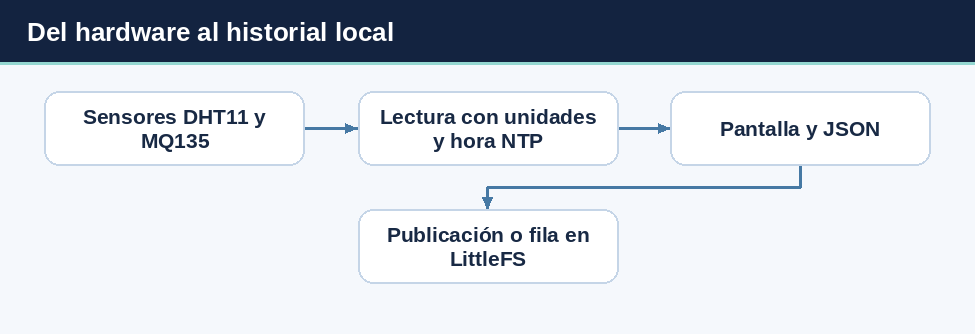

## Qué sucede con una lectura

Cada dos segundos `sampleAndPublish()` pide temperatura y humedad al DHT11. La estimación de gas usa ambas para compensación ambiental. El JSON conserva el valor de cada sensor y su unidad. La pantalla se refresca aunque el broker esté inalcanzable. Cuando el envío inmediato falla, el programa añade una fila a `/pending.csv`. Una vez restablecida la conexión envía la fila pendiente y solo desplaza el cursor después de recibir su ID de confirmación.

Hay tres momentos distintos durante la recuperación. Primero, el método MQTT local informa si aceptó el envío. Segundo, el broker confirma determinadas publicaciones QoS 1. Tercero, el mensaje de aplicación con el ID permite al ESP32 actualizar el cursor en NVS. El almacenamiento local protege contra varios fallos y la publicación en vivo sigue usando QoS 0.

## Ruta sugerida

1. [Sintaxis y conceptos C++](01_fundamentos_cpp_y_sintaxis.ipynb)
2. [Bibliotecas y estado](02_librerias_constantes_y_estado.ipynb)
3. [Arranque, ciclo y tiempo](03_arranque_conexion_y_tiempo.ipynb)
4. [Sensores, cálculos y JSON](04_sensores_json_y_pantalla.ipynb)
5. [LittleFS, CSV y NVS](05_csv_persistencia_y_confirmaciones.ipynb)
6. [Electrónica y medición](06_hardware_y_medicion.ipynb)
7. [Pantalla ST7789](07_pantalla_st7789.ipynb)
8. [PlatformIO, compilación y prácticas](08_configuracion_compilacion_y_practicas.ipynb)

Los diagramas explican el código vigente. Los bloques C++ son extractos. Los ejercicios Python calculan ejemplos o simulan datos en memoria.